<a href="https://colab.research.google.com/github/luisflhdz-ai/cfe-ami-anomalias/blob/main/Examen_practico_u5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Coeficiente principal (MedInc): 0.4487
MSE: 0.5559 | RMSE: 0.7456 | R²: 0.5758


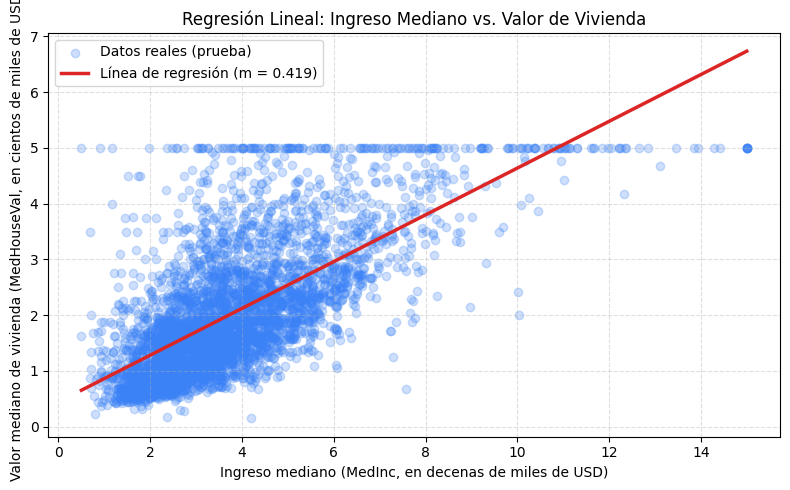

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Carga del dataset California Housing en formato DataFrame[cite: 5]
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# 2. Verificación de integridad y separación de matriz X y vector objetivo y[cite: 5]
assert df.isnull().sum().sum() == 0, "Existen valores nulos en el dataset"
X = df.drop(columns=["MedHouseVal"])  # Matriz de características (20,640 x 8)
y = df["MedHouseVal"]                 # Variable objetivo continua (valor de vivienda)

# 3. Partición entrenamiento/prueba (80% / 20%) con semilla fija para reproducibilidad[cite: 5]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 4. Ajuste del modelo de Regresión Lineal (Mínimos Cuadrados Ordinarios)[cite: 5]
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 5. Predicción en conjunto de prueba y evaluación con MSE, RMSE y R²[cite: 5]
y_pred = modelo.predict(X_test)
mse = mean_squared_error(y_test, y_pred)   # Penaliza errores grandes al cuadrado
rmse = np.sqrt(mse)                        # Error promedio en escala original ($100k USD)
r2 = r2_score(y_test, y_pred)              # Proporción de varianza explicada por el modelo

print(f"Coeficiente principal (MedInc): {modelo.coef_[0]:.4f}")
print(f"MSE: {mse:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

# 6. Visualización de dispersión y recta de regresión sobre el predictor más influyente[cite: 5]
modelo_simple = LinearRegression().fit(X_train[["MedInc"]], y_train)
x_linea = np.linspace(X_test["MedInc"].min(), X_test["MedInc"].max(), 200).reshape(-1, 1)
y_linea = modelo_simple.predict(pd.DataFrame(x_linea, columns=["MedInc"]))

plt.figure(figsize=(8, 5))
plt.scatter(X_test["MedInc"], y_test, alpha=0.25, color="#3b82f6", label="Datos reales (prueba)")
plt.plot(x_linea, y_linea, color="#dc2626", lw=2.5, label=f"Línea de regresión (m = {modelo_simple.coef_[0]:.3f})")
plt.title("Regresión Lineal: Ingreso Mediano vs. Valor de Vivienda")
plt.xlabel("Ingreso mediano (MedInc, en decenas de miles de USD)")
plt.ylabel("Valor mediano de vivienda (MedHouseVal, en cientos de miles de USD)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Registros limpios: 200 | Nulos: 0 | Duplicados: 0

    Ingreso_Anual_kUSD  Puntaje_Gasto  Tamano
0               55.09          51.60      40
1               89.53          17.20      40
2               25.52          80.40      40
3               25.05          19.47      40
4               87.28          82.60      40


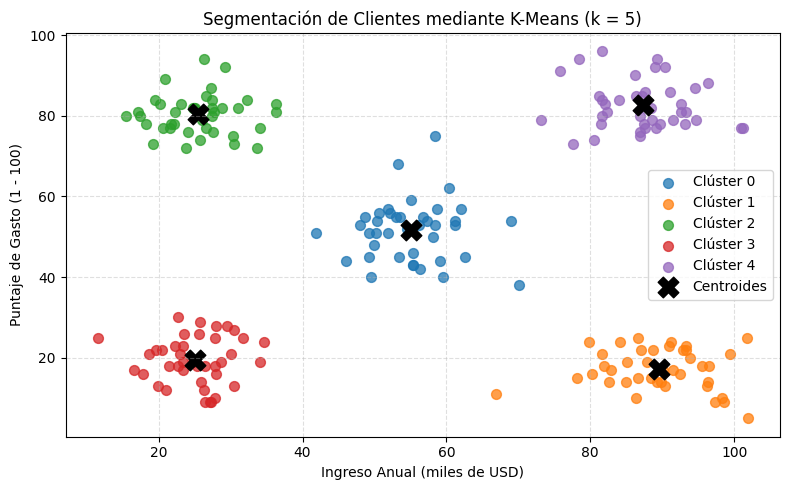

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Generación de datos estilo Mall Customers (200 registros, 5 segmentos base)
centros_base = [[26, 20], [26, 80], [55, 50], [88, 18], [87, 82]]
datos, _ = make_blobs(n_samples=200, centers=centros_base, cluster_std=[5.5, 5.5, 6.5, 6.5, 6.5], random_state=42)

df = pd.DataFrame(datos, columns=["Ingreso_Anual_kUSD", "Puntaje_Gasto"])
df["Ingreso_Anual_kUSD"] = df["Ingreso_Anual_kUSD"].round(2)
df["Puntaje_Gasto"] = df["Puntaje_Gasto"].clip(1, 100).round(0).astype(int)

# 2. Preprocesamiento: verificación de nulos/duplicados y escalamiento estándar
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"Registros limpios: {len(df)} | Nulos: {df.isnull().sum().sum()} | Duplicados: {df.duplicated().sum()}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["Ingreso_Anual_kUSD", "Puntaje_Gasto"]])

# 3. Selección de k óptimo: evaluación mediante Método del Codo (inercia) y Silhouette Score
inercias, silhouettes = [], []
k_rango = range(2, 11)

for k in k_rango:
    km_temp = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    etiquetas = km_temp.fit_predict(X_scaled)
    inercias.append(km_temp.inertia_)                          # Compacidad intra-clúster
    silhouettes.append(silhouette_score(X_scaled, etiquetas))  # Cohesión vs. separación

# 4. Entrenamiento del modelo final KMeans con k = 5 y asignación de etiquetas
kmeans = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Transformación inversa de centroides a escala original para interpretación de negocio
centroides_orig = scaler.inverse_transform(kmeans.cluster_centers_)
perfil_clusters = pd.DataFrame(centroides_orig, columns=["Ingreso_Anual_kUSD", "Puntaje_Gasto"]).round(2)
perfil_clusters["Tamano"] = df["Cluster"].value_counts().sort_index().values
print("\n", perfil_clusters)

# 6. Visualización de clústeres coloreados y centroides marcados
plt.figure(figsize=(8, 5))
for c in range(5):
    grupo = df[df["Cluster"] == c]
    plt.scatter(grupo["Ingreso_Anual_kUSD"], grupo["Puntaje_Gasto"], s=50, alpha=0.75, label=f"Clúster {c}")

plt.scatter(centroides_orig[:, 0], centroides_orig[:, 1], s=220, c="black", marker="X", label="Centroides")
plt.title("Segmentación de Clientes mediante K-Means (k = 5)")
plt.xlabel("Ingreso Anual (miles de USD)")
plt.ylabel("Puntaje de Gasto (1 - 100)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()